# Bài 5 (Trang 29) – Gom cụm khối u lành tính / ác tính (Breast Cancer Wisconsin)

**Họ tên:** Mai Quốc Đại — **MSSV:** 6451071013 — **Lớp:** CQ.64.CNTT

## Đọc dữ liệu Breast Cancer Wisconsin (Diagnostic)
File `wdbc.data`: cột 1 là ID, cột 2 là chẩn đoán (M = ác tính, B = lành tính), 30 cột còn lại là đặc trưng của nhân tế bào.

In [1]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

dac_trung = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
             "concavity", "concave_points", "symmetry", "fractal_dimension"]
columns = ["id", "diagnosis"] + [f"{f}_{s}" for s in ["mean", "se", "worst"] for f in dac_trung]
df = pd.read_csv("data/breast_cancer/wdbc.data", header=None, names=columns)
print("Kích thước:", df.shape)
print(df.iloc[:5, :8])
print("\nSố giá trị thiếu:", int(df.isnull().sum().sum()))
print("\nPhân bố nhãn chẩn đoán:"); print(df["diagnosis"].value_counts())

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


Kích thước: (569, 32)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  compactness_mean
0    842302         M        17.99         10.38          122.80     1001.0          0.11840           0.27760
1    842517         M        20.57         17.77          132.90     1326.0          0.08474           0.07864
2  84300903         M        19.69         21.25          130.00     1203.0          0.10960           0.15990
3  84348301         M        11.42         20.38           77.58      386.1          0.14250           0.28390
4  84358402         M        20.29         14.34          135.10     1297.0          0.10030           0.13280

Số giá trị thiếu: 0

Phân bố nhãn chẩn đoán:
diagnosis
B    357
M    212
Name: count, dtype: int64


## Tiền xử lý
Các đặc trưng có thang đo rất khác nhau (ví dụ `area` hàng nghìn, `smoothness` ~0.1), nên chuẩn hóa z-score trước khi gom cụm. Nhãn `diagnosis` chỉ dùng để đánh giá, không đưa vào thuật toán.

In [2]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
X = df.drop(columns=["id", "diagnosis"]).values
y_true = (df["diagnosis"] == "M").astype(int).values   # 1 = ác tính, 0 = lành tính
X_scaled = StandardScaler().fit_transform(X)
print("X_scaled:", X_scaled.shape, "- mean ~", round(X_scaled.mean(), 4), "- std ~", round(X_scaled.std(), 4))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
X_scaled: (569, 30) - mean ~ -0.0 - std ~ 1.0


## Khảo sát số cụm: Elbow và Silhouette

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


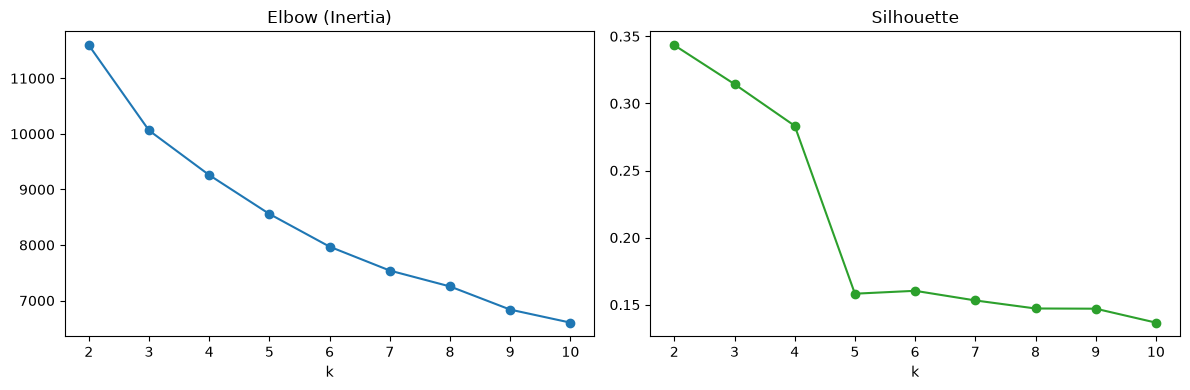

k =  2: inertia =   11595.5 - silhouette = 0.3434
k =  3: inertia =   10061.8 - silhouette = 0.3144
k =  4: inertia =    9259.0 - silhouette = 0.2833
k =  5: inertia =    8558.7 - silhouette = 0.1582
k =  6: inertia =    7970.3 - silhouette = 0.1604
k =  7: inertia =    7540.3 - silhouette = 0.1532
k =  8: inertia =    7254.3 - silhouette = 0.1472
k =  9: inertia =    6837.6 - silhouette = 0.1470
k = 10: inertia =    6603.4 - silhouette = 0.1367


In [3]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
inertia, sil = [], []
ks = range(2, 11)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_); sil.append(metrics.silhouette_score(X_scaled, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertia, "o-"); ax[0].set_title("Elbow (Inertia)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sil, "o-", color="tab:green"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
for k, i, s in zip(ks, inertia, sil):
    print(f"k = {k:2d}: inertia = {i:9.1f} - silhouette = {s:.4f}")

## Gom cụm k-Means với k = 2 (lành tính / ác tính)

In [4]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_scaled)
print("Số phần tử mỗi cụm:", np.bincount(clusters))
print("Silhouette:", round(metrics.silhouette_score(X_scaled, clusters), 4))
# Gán nhãn cho cụm theo đa số
cluster_to_label = {c: int(np.bincount(y_true[clusters == c]).argmax()) for c in range(2)}
for c, l in cluster_to_label.items():
    print(f"Cụm {c} -> {'Ác tính (M)' if l == 1 else 'Lành tính (B)'}")
y_pred = np.array([cluster_to_label[c] for c in clusters])

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Số phần tử mỗi cụm: [375 194]
Silhouette: 0.3434
Cụm 0 -> Lành tính (B)
Cụm 1 -> Ác tính (M)


## So sánh với nhãn chẩn đoán thực tế

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Accuracy: 0.9051
Adjusted Rand Index: 0.6536
               precision    recall  f1-score   support

Lành tính (B)     0.9040    0.9496    0.9262       357
  Ác tính (M)     0.9072    0.8302    0.8670       212

     accuracy                         0.9051       569
    macro avg     0.9056    0.8899    0.8966       569
 weighted avg     0.9052    0.9051    0.9042       569



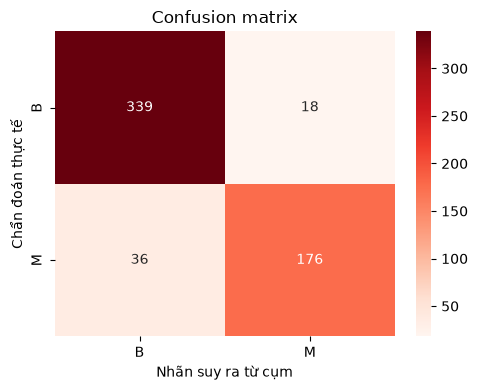

In [5]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Adjusted Rand Index:", round(metrics.adjusted_rand_score(y_true, clusters), 4))
print(classification_report(y_true, y_pred, target_names=["Lành tính (B)", "Ác tính (M)"], digits=4))
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds",
            xticklabels=["B", "M"], yticklabels=["B", "M"])
plt.xlabel("Nhãn suy ra từ cụm"); plt.ylabel("Chẩn đoán thực tế"); plt.title("Confusion matrix")
plt.tight_layout(); plt.show()

## Trực quan hóa bằng PCA 2 chiều

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Tỷ lệ phương sai giải thích bởi 2 thành phần: [0.4427 0.1897]


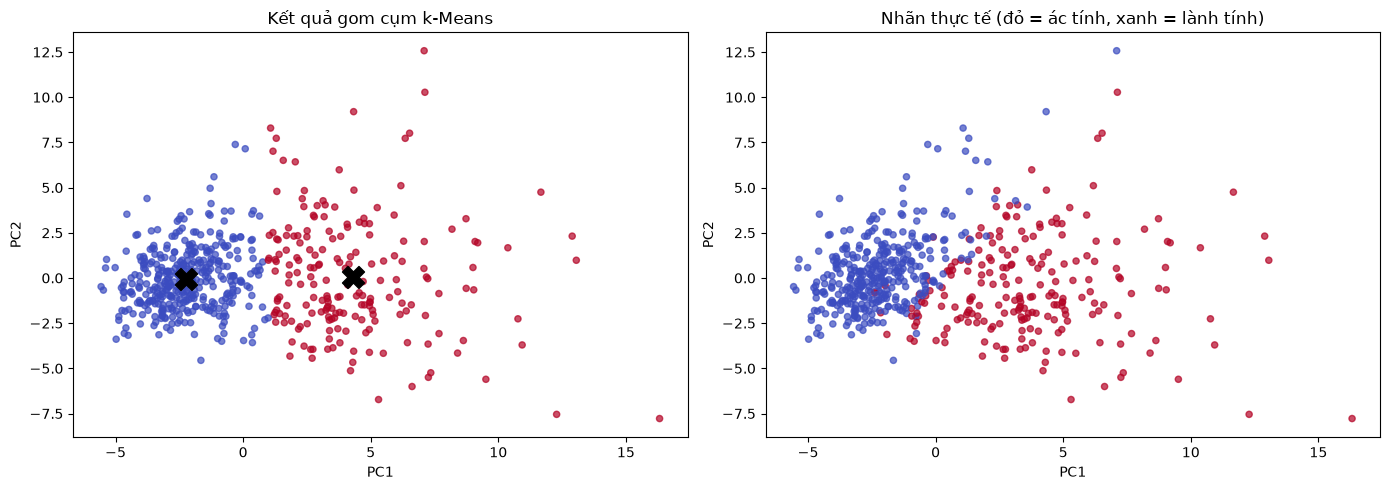

In [6]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
C_pca = pca.transform(kmeans.cluster_centers_)
print("Tỷ lệ phương sai giải thích bởi 2 thành phần:", np.round(pca.explained_variance_ratio_, 4))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap="coolwarm", s=20, alpha=0.7)
ax[0].scatter(C_pca[:, 0], C_pca[:, 1], c="black", s=250, marker="X")
ax[0].set_title("Kết quả gom cụm k-Means")
ax[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap="coolwarm", s=20, alpha=0.7)
ax[1].set_title("Nhãn thực tế (đỏ = ác tính, xanh = lành tính)")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Nhận xét:**

- Theo silhouette, k = 2 là số cụm tốt nhất (0.3434), phù hợp với hai nhóm lành tính / ác tính của bài toán.
- k-Means với k = 2 (không dùng nhãn khi huấn luyện) cho kết quả khớp với chẩn đoán thực tế ở mức **Accuracy ≈ 90.5%** (ARI ≈ 0.65). Lớp lành tính có recall 0.95, lớp ác tính có recall 0.83: khoảng 17% khối u ác tính bị xếp vào cụm lành tính.
- Trên biểu đồ PCA, hai nhóm tách khá rõ dọc theo trục PC1 (liên quan đến kích thước nhân tế bào như radius, perimeter, area), nhưng vùng giáp ranh có chồng lấn nên k-Means không phân tách được hoàn toàn.
- Trong y tế, bỏ sót ca ác tính là sai lầm nghiêm trọng. Gom cụm hữu ích để khám phá cấu trúc dữ liệu, nhưng chẩn đoán thực tế cần mô hình có giám sát và chuyên gia kiểm tra.